In [1]:
import os
import random
import numpy as np
import pandas as pd

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(SEED)

In [7]:
def build_universal_dataset(file_paths):
    combined_dfs = []
    
    for loc_id, (loc_name, path) in enumerate(file_paths.items(), 1):
        df = pd.read_csv(path)
        
        # A) LOKASYON KİMLİĞİ (Identity)
        df['location_id'] = f"Loc_{loc_id}"
        
        # B) TARİH VE ZAMAN DÖNGÜSEL (CYCLIC) ÖZNİTELİKLERİ
        df['Time'] = pd.to_datetime(df['Time'])
        df['hour'] = df['Time'].dt.hour
        df['month'] = df['Time'].dt.month
        df['dayofweek'] = df['Time'].dt.dayofweek
        
        # Saatlik ve Aylık Sin/Cos Dönüşümleri (24 saat ve 12 ay döngüsü için)
        df['sin_hour'] = np.sin(2 * np.pi * df['hour'] / 24.0)
        df['cos_hour'] = np.cos(2 * np.pi * df['hour'] / 24.0)
        df['sin_month'] = np.sin(2 * np.pi * df['month'] / 12.0)
        df['cos_month'] = np.cos(2 * np.pi * df['month'] / 12.0)
        
        # C) RÜZGAR YÖNÜ DÖNGÜSEL (CYCLIC) DÖNÜŞÜMLERİ (1°-359° Çelişkisini Çözer)
        # Dereceler radyana çevrilip Sin ve Cosine bileşenleri alınır
        df['wind_dir_100m_sin'] = np.sin(np.radians(df['winddirection_100m']))
        df['wind_dir_100m_cos'] = np.cos(np.radians(df['winddirection_100m']))
        
        # 100 metre için rüzgar yönüyle yüksek korelasyona sahip olduğundan
        # ve rüzgar kayma katsayısının yeterli olmasından ötürü 10 metre için rüzgar yönü alınmayacak
        # df['wind_dir_10m_sin'] = np.sin(np.radians(df['winddirection_10m']))
        # df['wind_dir_10m_cos'] = np.cos(np.radians(df['winddirection_10m']))
        
        # D) METEOROLOJİK FİZİK TABANLI TÜREV ÖZNİTELİKLER
        # Epsilon (0.001) ile 0'a bölünme hataları önlenir
        eps = 0.001
        
        # 1. Rüzgar Kayma Katsayısı (Wind Shear Ratio)
        df['wind_shear_ratio'] = df['windspeed_100m'] / (df['windspeed_10m'] + eps)
        
        # 2. Türbülans ve Gust Oranı (Gust Ratio - 10m Gust'ın bağıl etkisi)
        df['gust_ratio'] = df['windgusts_10m'] / (df['windspeed_10m'] + eps)
        
        # 3. Çiğ Noktası Açığı (Sıcaklık ve Nem Doygunluk Farkı)
        df['temp_dew_spread'] = df['temperature_2m'] - df['dewpoint_2m']
        
        # E) ZAMAN SERİSİ GECİKME (LAG) ÖZNİTELİKLERİ
        df['windspeed_100m_lag1'] = df['windspeed_100m'].shift(1)
        df['Power_lag1'] = df['Power'].shift(1)

         # F) 1 SAATLİK GECİKME SUTÜNUNA BAĞLILIĞI KIRMAK İÇİN HAREKET YÖNÜ 
        df['Power_diff1'] = df['Power_lag1'] - df['Power'].shift(2)
        df['windspeed_100m_diff1'] = df['windspeed_100m_lag1'] - df['windspeed_100m'].shift(2)
        
        # F) GEREKSİZ / YÜKSEK KORELASYONLU HAM SÜTUNLARIN TEMİZLENMESİ (DROP)
        # - windspeed_10m: 100m ile +0.90 korelasyonlu, bilgisi wind_shear_ratio'ya aktarıldı
        # - dewpoint_2m: Sıcaklık ile yüksek korelasyonlu, bilgisi temp_dew_spread'e aktarıldı
        # - windgusts_10m: Mutlak değeri silindi, bilgisi gust_ratio'ya aktarıldı
        # - winddirection_10m / 100m: Derece hali silindi, Sin/Cos bileşenleri korundu
        # - Time, hour, month: Ham halleri çıkarıldı. Döngüsel halleri tutuldu
        # - Bağıl nem (relativehumidity_2m) ile Çiğ noktası açığı yüksek korelasyonlu (-0.98). relativehumidity_2m silindi
        drop_cols = [
            'Time', 'hour', 'month', 'dewpoint_2m', 'windspeed_10m', 
            'windgusts_10m', 'winddirection_10m', 'winddirection_100m', 'relativehumidity_2m'
        ]
        df.drop(columns=drop_cols, inplace=True)
        
        combined_dfs.append(df)
    
    # Tüm lokasyonları tek bir dev veri setinde birleştirme (Concatenation)
    universal_df = pd.concat(combined_dfs, ignore_index=True)
    
    # Lag işlemlerinden doğan ilk satırdaki NaN değerleri temizleme
    universal_df.dropna(inplace=True)
    universal_df.reset_index(drop=True, inplace=True)
    
    # G) KATEGORİK LOKASYON BİLGİSİNİ ONE-HOT ENCODING YAPMA
    universal_df = pd.get_dummies(universal_df, columns=['location_id'], drop_first=False)
    
    return universal_df


In [12]:
# UYGULAMA VE VERİ SETİNİ KAYDETME
file_paths = {
    "Lokasyon 1": "Location1.csv",
    "Lokasyon 2": "Location2.csv",
    "Lokasyon 3": "Location3.csv",
    "Lokasyon 4": "Location4.csv"
}

# Evrensel Veri Setinin Üretilmesi ve Kaydedilmesi
universal_df = build_universal_dataset(file_paths)

print("EVRENSEL VERİ SETİ BAŞARIYLA OLUŞTURULDU")
print(f"Toplam Satır ve Sütun Sayısı: {universal_df.shape}")
print("\nModel Eğitimine Hazır Sütun Listesi:")
for col in universal_df.columns:
    print(f" - {col}")

universal_df.to_csv("Universal_Wind_Dataset.csv", index=False)

EVRENSEL VERİ SETİ BAŞARIYLA OLUŞTURULDU
Toplam Satır ve Sütun Sayısı: (175192, 21)

Model Eğitimine Hazır Sütun Listesi:
 - temperature_2m
 - windspeed_100m
 - Power
 - dayofweek
 - sin_hour
 - cos_hour
 - sin_month
 - cos_month
 - wind_dir_100m_sin
 - wind_dir_100m_cos
 - wind_shear_ratio
 - gust_ratio
 - temp_dew_spread
 - windspeed_100m_lag1
 - Power_lag1
 - Power_diff1
 - windspeed_100m_diff1
 - location_id_Loc_1
 - location_id_Loc_2
 - location_id_Loc_3
 - location_id_Loc_4


In [9]:
universal_df.head(10)

,temperature_2m,windspeed_100m,Power,dayofweek,sin_hour,cos_hour,sin_month,cos_month,wind_dir_100m_sin,wind_dir_100m_cos,...,gust_ratio,temp_dew_spread,windspeed_100m_lag1,Power_lag1,Power_diff1,windspeed_100m_diff1,location_id_Loc_1,location_id_Loc_2,location_id_Loc_3,location_id_Loc_4
0,26.8,2.78,0.1214,0,0.500000,8.660254e-01,0.5,0.866025,0.500000,-0.866025,...,2.459646,2.3,3.99,0.1424,-0.0211,2.73,True,False,False,False
1,27.4,2.69,0.1003,0,0.707107,7.071068e-01,0.5,0.866025,0.965926,-0.258819,...,1.229823,3.1,2.78,0.1214,-0.0210,-1.21,True,False,False,False
2,27.3,4.43,0.0793,0,0.866025,5.000000e-01,0.5,0.866025,0.994522,0.104528,...,1.618778,3.2,2.69,0.1003,-0.0211,-0.09,True,False,False,False
3,27.6,5.59,0.0778,0,0.965926,2.588190e-01,0.5,0.866025,0.984808,0.173648,...,1.647748,2.4,4.43,0.0793,-0.0210,1.74,True,False,False,False
4,26.7,5.82,0.0959,0,1.000000,6.123234e-17,0.5,0.866025,0.978148,0.207912,...,2.237030,1.8,5.59,0.0778,-0.0015,1.16,True,False,False,False
5,28.4,6.24,0.1141,0,0.965926,-2.588190e-01,0.5,0.866025,0.978148,0.207912,...,1.547888,2.3,5.82,0.0959,0.0181,0.23,True,False,False,False
6,30.2,6.89,0.1322,0,0.866025,-5.000000e-01,0.5,0.866025,0.987688,0.156434,...,1.637955,3.2,6.24,0.1141,0.0182,0.42,True,False,False,False
7,34.0,6.01,0.1503,0,0.707107,-7.071068e-01,0.5,0.866025,0.997564,0.069756,...,1.888986,4.9,6.89,0.1322,0.0181,0.65,True,False,False,False
8,35.6,5.32,0.1684,0,0.500000,-8.660254e-01,0.5,0.866025,0.996195,-0.087156,...,2.155753,7.9,6.01,0.1503,0.0181,-0.88,True,False,False,False
9,36.2,4.65,0.1866,0,0.258819,-9.659258e-01,0.5,0.866025,0.987688,-0.156434,...,2.514747,9.2,5.32,0.1684,0.0181,-0.69,True,False,False,False


In [10]:
universal_df.tail(10)

,temperature_2m,windspeed_100m,Power,dayofweek,sin_hour,cos_hour,sin_month,cos_month,wind_dir_100m_sin,wind_dir_100m_cos,...,gust_ratio,temp_dew_spread,windspeed_100m_lag1,Power_lag1,Power_diff1,windspeed_100m_diff1,location_id_Loc_1,location_id_Loc_2,location_id_Loc_3,location_id_Loc_4
175182,29.5,3.61,0.1506,4,-0.500000,-8.660254e-01,-2.449294e-16,1.0,0.996195,0.087156,...,1.938426,3.7,3.72,0.0929,0.0578,-0.52,False,False,False,True
175183,30.0,3.98,0.2084,4,-0.707107,-7.071068e-01,-2.449294e-16,1.0,0.777146,0.629320,...,1.820884,3.7,3.61,0.1506,0.0577,-0.11,False,False,False,True
175184,29.4,5.57,0.2662,4,-0.866025,-5.000000e-01,-2.449294e-16,1.0,0.358368,0.933580,...,1.624492,3.3,3.98,0.2084,0.0578,0.37,False,False,False,True
175185,28.4,7.51,0.3240,4,-0.965926,-2.588190e-01,-2.449294e-16,1.0,0.173648,0.984808,...,1.666306,2.7,5.57,0.2662,0.0578,1.59,False,False,False,True
175186,26.2,7.69,0.3492,4,-1.000000,-1.836970e-16,-2.449294e-16,1.0,0.275637,0.961262,...,1.867969,2.0,7.51,0.3240,0.0578,1.94,False,False,False,True
175187,25.5,6.66,0.3417,4,-0.965926,2.588190e-01,-2.449294e-16,1.0,0.139173,0.990268,...,2.044378,1.5,7.69,0.3492,0.0252,0.18,False,False,False,True
175188,25.3,7.52,0.3342,4,-0.866025,5.000000e-01,-2.449294e-16,1.0,0.087156,0.996195,...,1.680494,2.1,6.66,0.3417,-0.0075,-1.03,False,False,False,True
175189,24.9,7.57,0.3267,4,-0.707107,7.071068e-01,-2.449294e-16,1.0,0.139173,0.990268,...,1.713294,2.4,7.52,0.3342,-0.0075,0.86,False,False,False,True
175190,24.9,7.44,0.3192,4,-0.500000,8.660254e-01,-2.449294e-16,1.0,0.104528,0.994522,...,1.695284,2.8,7.57,0.3267,-0.0075,0.05,False,False,False,True
175191,24.9,7.77,0.3117,4,-0.258819,9.659258e-01,-2.449294e-16,1.0,0.207912,0.978148,...,1.677059,3.1,7.44,0.3192,-0.0075,-0.13,False,False,False,True


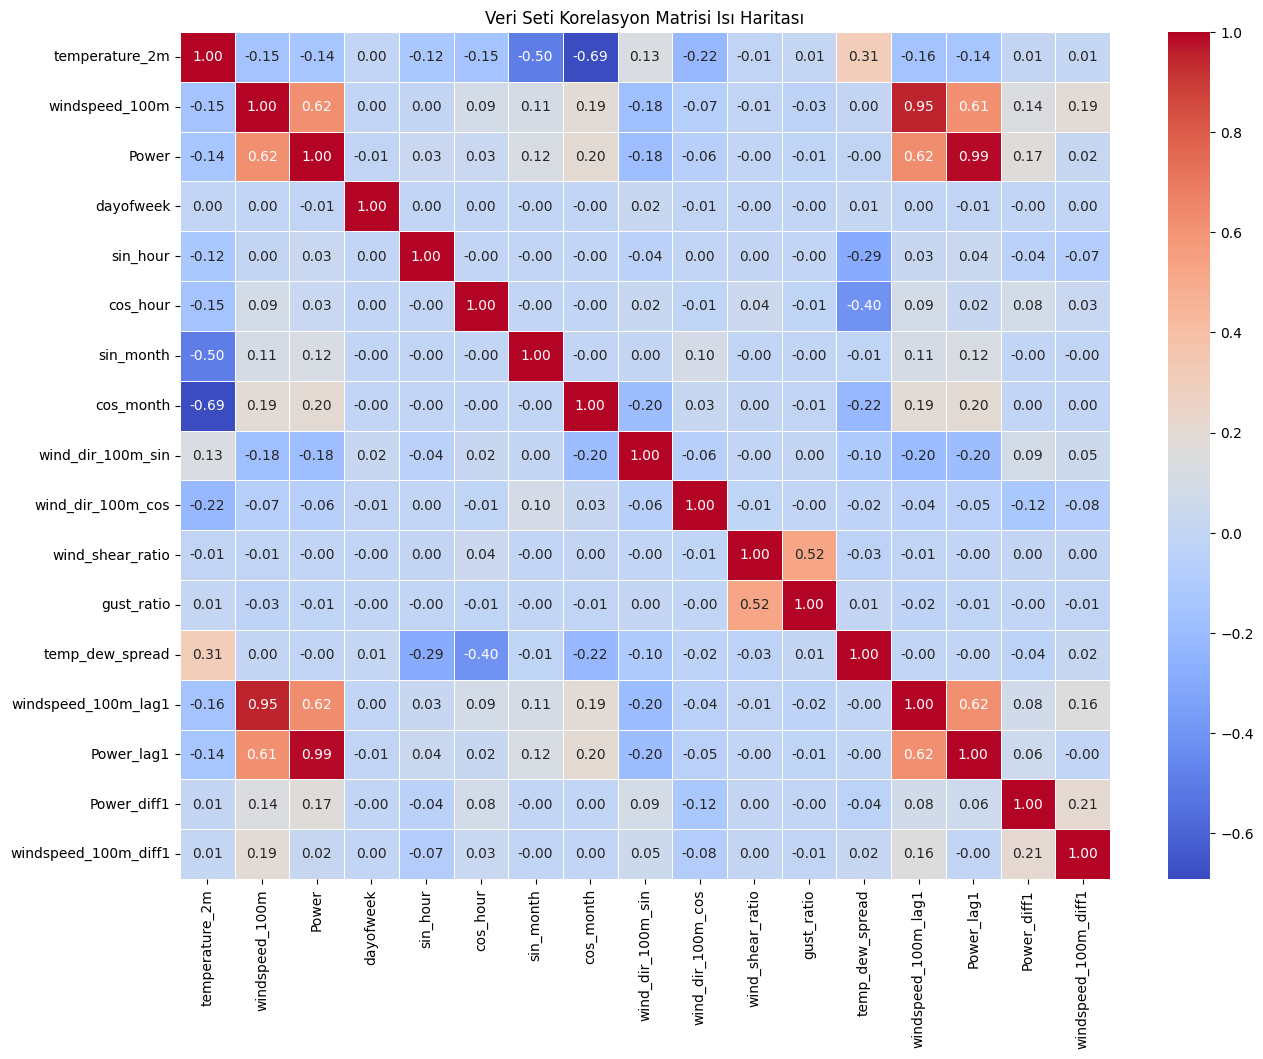

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# One-hot sütunlarının isim örüntülerini yakalayıp dışarıda bırakıyoruz
one_hot_cols = [col for col in universal_df.columns if 'location_id_' in col]

# Sadece gerçek sürekli sayısal sütunları seçiyoruz
gercek_sayisal_df = universal_df.select_dtypes(include=['number']).drop(columns=one_hot_cols, errors='ignore')

# Korelasyonu sadece bunlarla hesaplıyoruz
korelasyon_matrisi = gercek_sayisal_df.corr()

plt.figure(figsize=(15, 11))
sns.heatmap(korelasyon_matrisi, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Veri Seti Korelasyon Matrisi Isı Haritası')
plt.savefig("universal_korelasyon_matrisi.png", dpi=300)
plt.show()

EVRENSEL DATASETİN BÖLÜNMESİ

In [18]:
# LOKASYON BAZLI ADİL ZAMAN SERİSİ BÖLME
def split_location_balanced(df, target_col='Power', train_ratio=0.70, val_ratio=0.15):
    
    # Her lokasyonu kendi içinde %70 Train, %15 Val, %15 Test olarak kronolojik böler
    # ve ardından bu setleri birleştirerek evrensel Train, Val ve Test setleri oluşturur.
    
    train_dfs, val_dfs, test_dfs = [], [], []
    
    # Lokasyon kolonlarını tespit et (location_id_Loc_1, location_id_Loc_2 vb.)
    loc_cols = [col for col in df.columns if col.startswith('location_id_')]
    
    for loc_col in loc_cols:
        # İlgili lokasyona ait verileri süz
        loc_df = df[df[loc_col] == 1].copy()
        
        n = len(loc_df)
        train_end = int(n * train_ratio)
        val_end = int(n * (train_ratio + val_ratio))
        
        # Lokasyon bazlı kronolojik bölme
        train_dfs.append(loc_df.iloc[:train_end])
        val_dfs.append(loc_df.iloc[train_end:val_end])
        test_dfs.append(loc_df.iloc[val_end:])
    
    # Tüm lokasyonların Train, Val ve Test parçalarını birleştirme
    train_full = pd.concat(train_dfs, ignore_index=True)
    val_full = pd.concat(val_dfs, ignore_index=True)
    test_full = pd.concat(test_dfs, ignore_index=True)
    
    # X (Girdiler) ve y (Hedef Değişken) ayrımı
    X_train, y_train = train_full.drop(columns=[target_col]), train_full[target_col]
    X_val, y_val = val_full.drop(columns=[target_col]), val_full[target_col]
    X_test, y_test = test_full.drop(columns=[target_col]), test_full[target_col]
    
    return X_train, y_train, X_val, y_val, X_test, y_test

# Setlerin Oluşturulması
X_tr_univ, y_tr_univ, X_val_univ, y_val_univ, X_te_univ, y_te_univ = split_location_balanced(universal_df)

# 3. KONTROL VE BOYUT ÖZETİ
print(" DENGELİ EVRENSEL VERİ BÖLME ÖZETİ ")
print(f"Evrensel Train Seti : {X_tr_univ.shape[0]} satır (Tüm lokasyonların %70'i)")
print(f"Evrensel Val Seti   : {X_val_univ.shape[0]} satır (Tüm lokasyonların %15'i)")
print(f"Evrensel Test Seti  : {X_te_univ.shape[0]} satır (Tüm lokasyonların %15'i)")
print(f"Girdi Öznitelik Sayısı (Feature Count): {X_tr_univ.shape[1]}")

 DENGELİ EVRENSEL VERİ BÖLME ÖZETİ 
Evrensel Train Seti : 122632 satır (Tüm lokasyonların %70'i)
Evrensel Val Seti   : 26280 satır (Tüm lokasyonların %15'i)
Evrensel Test Seti  : 26280 satır (Tüm lokasyonların %15'i)
Girdi Öznitelik Sayısı (Feature Count): 20


In [19]:
X_tr_univ.head()

,temperature_2m,windspeed_100m,dayofweek,sin_hour,cos_hour,sin_month,cos_month,wind_dir_100m_sin,wind_dir_100m_cos,wind_shear_ratio,gust_ratio,temp_dew_spread,windspeed_100m_lag1,Power_lag1,Power_diff1,windspeed_100m_diff1,location_id_Loc_1,location_id_Loc_2,location_id_Loc_3,location_id_Loc_4
0,26.8,2.78,0,0.500000,8.660254e-01,0.5,0.866025,0.500000,-0.866025,2.136818,2.459646,2.3,3.99,0.1424,-0.0211,2.73,True,False,False,False
1,27.4,2.69,0,0.707107,7.071068e-01,0.5,0.866025,0.965926,-0.258819,2.067640,1.229823,3.1,2.78,0.1214,-0.0210,-1.21,True,False,False,False
2,27.3,4.43,0,0.866025,5.000000e-01,0.5,0.866025,0.994522,0.104528,1.792796,1.618778,3.2,2.69,0.1003,-0.0211,-0.09,True,False,False,False
3,27.6,5.59,0,0.965926,2.588190e-01,0.5,0.866025,0.984808,0.173648,2.046869,1.647748,2.4,4.43,0.0793,-0.0210,1.74,True,False,False,False
4,26.7,5.82,0,1.000000,6.123234e-17,0.5,0.866025,0.978148,0.207912,2.770109,2.237030,1.8,5.59,0.0778,-0.0015,1.16,True,False,False,False
